In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Module_01_User_and_Body_Profile.md").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from IPython.display import display, Markdown


# 02 — InBody preprocessing

**Research question:** Có thể chuẩn hóa ảnh/PDF mà giữ toàn bộ thông tin và ảnh nguồn không?

Dataset: synthetic v1, seed 42. Baseline: EXIF transpose → grayscale → autocontrast; chưa tự crop/deskew/denoise khi chưa có benchmark đối chứng.

exif-gray-autocontrast-0.1.0 1 pages; original unchanged


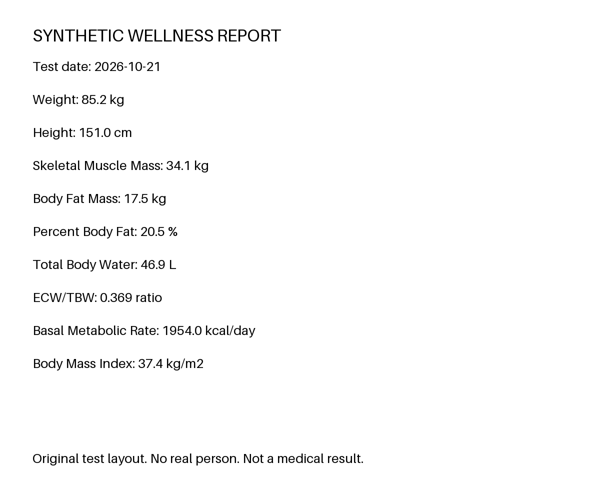

In [2]:
from src.document_ai.ocr import preprocess_document
manifest = json.loads((ROOT / "data/manifests/inbody_synthetic_v1.json").read_text(encoding="utf-8"))
sample = manifest["samples"][0]
raw = ROOT / sample["image"]
import hashlib
before = hashlib.sha256(raw.read_bytes()).hexdigest()
result = preprocess_document(raw, ROOT / "data/processed/inbody_preprocessing_demo")
assert before == result["source_sha256"] == hashlib.sha256(raw.read_bytes()).hexdigest()
print(result["preprocessing_version"], len(result["pages"]), "pages; original unchanged")
from PIL import Image
display(Image.open(result["pages"][0]).resize((600, 500)))

## Metrics / error analysis / conclusion

Đã kiểm tra không đổi file gốc, số trang và render PDF trong unit tests. Giới hạn nghiên cứu: file ≤30 MiB, ≤5 trang, ≤25 triệu pixel/trang sau render. Chưa đánh giá lợi ích cho CER/WER hoặc biến dạng phối cảnh. Cần thí nghiệm raw vs grayscale vs deskew trên phiếu thật trước lựa chọn preprocessing tốt nhất.